# k-means clustering (baseline)

customer segmentation on `train.csv` from `preprocessing.ipynb`. run that notebook first.

both targets (`IsCanceled`, `ADR`) stay out of the model and are only used to describe the clusters.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data/processed"


## load the training data


In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
train.shape


(31007, 20)

## choose the features

dropped from clustering:
- `IsCanceled`, `ADR`: targets.
- `Agent`: anonymised id with many values.
- arrival date columns: calendar position, not customer type.

`Children` has a few missing values, filled with the median.


In [3]:
numerical_features = [
    "LeadTime",
    "StaysInWeekendNights",
    "StaysInWeekNights",
    "Adults",
    "Children",
    "Babies",
    "HasCompany",
]
categorical_features = [
    "Meal",
    "MarketSegment",
    "DistributionChannel",
    "ReservedRoomType",
    "CustomerType",
]

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])

X_train = preprocess.fit_transform(train[numerical_features + categorical_features])
X_train.shape


(31007, 35)

## pick k

elbow on the training rows.


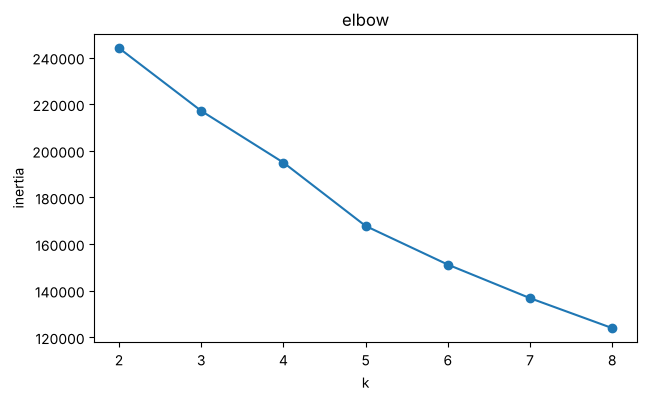

In [4]:
inertias = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_train)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(2, 9), inertias, marker="o")
plt.title("elbow")
plt.xlabel("k")
plt.ylabel("inertia")
plt.show()


we use k = 4.


In [5]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
train["Cluster"] = kmeans.fit_predict(X_train)
train["Cluster"].value_counts().sort_index()


Cluster
0     5764
1    17837
2     5866
3     1540
Name: count, dtype: int64

## profile the clusters

numbers are cluster means; categories show the most common value.


In [6]:
profile = train.groupby("Cluster").agg(
    bookings=("LeadTime", "size"),
    **{col: (col, "mean") for col in numerical_features + ["ADR", "IsCanceled"]},
    **{col: (col, lambda s: s.mode().iat[0]) for col in categorical_features},
)
profile.round(2)


,bookings,LeadTime,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,HasCompany,ADR,IsCanceled,Meal,MarketSegment,DistributionChannel,ReservedRoomType,CustomerType
Cluster,,,,,,,,,,,,,,,
0,5764,274.74,0.58,1.91,1.96,0.00,0.00,0.0,79.09,0.77,BB,Groups,TA/TO,A,Transient-Party
1,17837,53.51,0.86,2.16,2.05,0.09,0.01,0.0,99.94,0.34,BB,Online TA,TA/TO,A,Transient
2,5866,62.31,0.64,1.98,1.00,0.02,0.00,0.0,90.68,0.37,BB,Offline TA/TO,TA/TO,A,Transient
3,1540,22.87,0.39,1.56,1.25,0.01,0.00,1.0,73.77,0.20,BB,Corporate,Corporate,A,Transient


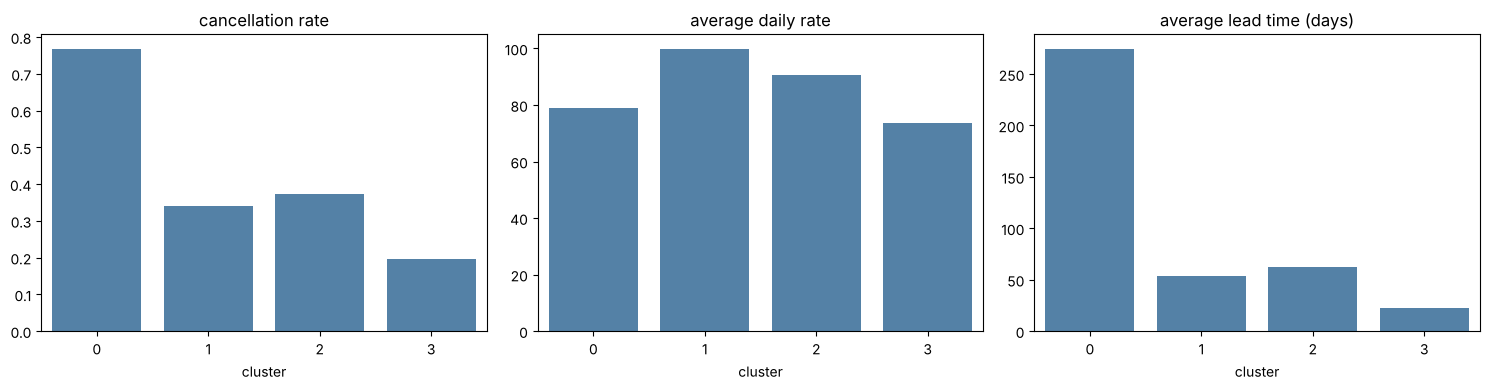

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for column, label, ax in zip(
    ["IsCanceled", "ADR", "LeadTime"],
    ["cancellation rate", "average daily rate", "average lead time (days)"],
    axes,
):
    sns.barplot(data=train, x="Cluster", y=column, color="steelblue", errorbar=None, ax=ax)
    ax.set(title=label, xlabel="cluster", ylabel="")
plt.tight_layout()
plt.show()
